# 0-instruments: dmm

Find out how late the DMM's Bluetooth log is against the host clock, so later notebooks can line it up with the DPS and the board.

## Purpose

Several later experiments log the DMM next to something logged on the host clock: the DPS readback in stage 1, the board's telemetry in stages 2 and 3. Lining those logs up needs the DMM's delay. A delay of tenths of a second is harmless for a resistance that changes over minutes. A delay of seconds would shift every thermal curve read through the DMM. This experiment measures the delay directly, and with it the DMM's packet rate, which is the finest time resolution any DMM log in this repo can have.

The DMM's reading accuracy is not measured here. It comes from the manual and is copied into the result as a note.

## Procedure

The DMM is clipped across the DPS output terminals, set to DC V, with Bluetooth on. Nothing else is connected to the DPS. `capture.py` then

1. starts logging the DMM over Bluetooth, one row per packet with the host time it arrived,
2. steps the DPS between 3 V and three higher levels, twelve steps of 10 s, writing the host time of each set command,
3. logs the DPS's own voltage readback on the host clock at about 1.5 Hz throughout.

Every step is at least 3 V, large against the DMM's noise, and every level is under the 20 V range so the DMM does not change range during a step.

## Data

Three files in the dataset folder, all on the same host clock. Each is shown on its own first.

### dmm.csv

One row per DMM packet. `t_host` is the host time the packet arrived, `function` the DMM's mode (`DC V` throughout this run), `value` the reading in volts, `raw` the six-byte packet in hex. `b41t.load` adds `t`, seconds from the first row.

,t_host,function,value,raw,t
0,22:53:22.071,DC V,-0.001,24f004000780,0.000
1,22:53:22.657,DC V,-0.001,24f004000780,0.587
2,22:53:23.048,DC V,-0.001,24f004000780,0.977
3,22:53:23.632,DC V,-0.001,24f004000780,1.562
4,22:53:24.217,DC V,-0.001,24f004000780,2.147


262 DC V rows


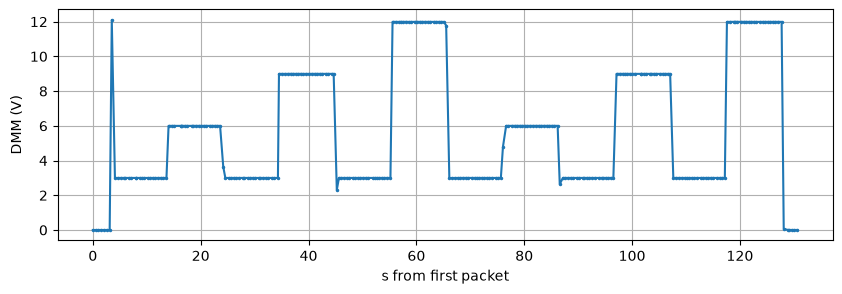

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import b41t, results, show

CAPTURE = Path("../../../telemetry/instruments/dmm/capture-1").resolve()

dmm = b41t.load(CAPTURE / "dmm.csv")
show(dmm)
dmm = dmm[dmm.function == "DC V"].dropna(subset=["value"]).reset_index(drop=True)
print(len(dmm), "DC V rows")
dmm.plot(x="t", y="value", style=".-", ms=3, figsize=(10, 3), grid=True, legend=False, ylabel="DMM (V)", xlabel="s from first packet");

The DMM's view of the run on its own: the voltage it displayed, at the moments the host received it. The square steps are the DPS changing level. The brief spike to 12 V at the start is the DPS output coming up at its previous setting for a moment before the 3 V set command took hold; the DPS's own log in the next section catches only its tail. It is outside every step window and does not enter the analysis, but a load that minds a 12 V pulse should not be on the DPS when its output is enabled.

### dps.csv

The DPS's readback of its own output, polled by the host. `t_host`, `volts` and `amps`. The `amps` column is not used anywhere in this repo; the DPS reads current well under the true value, see the equipment notes.

,t_host,volts,amps
0,22:53:25.608,1.551,0.000
1,22:53:26.257,3.000,0.000
2,22:53:26.908,3.000,0.000
3,22:53:27.561,3.000,0.000
4,22:53:28.211,3.000,0.000


192 rows, 1.5 Hz


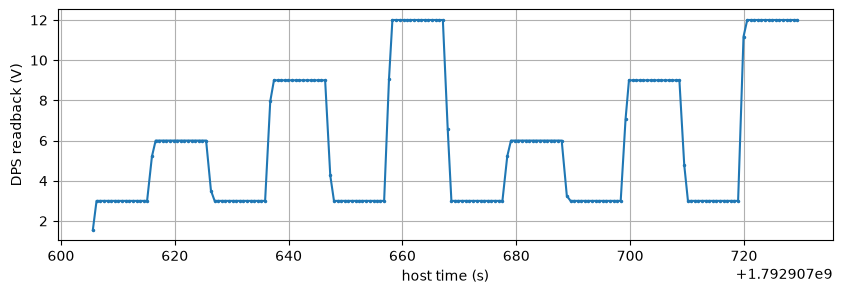

In [2]:
dps = pd.read_csv(CAPTURE / "dps.csv")
show(dps)
print(len(dps), "rows,", f"{1 / np.median(np.diff(dps.t_host)):.1f} Hz")
dps.plot(x="t_host", y="volts", style=".-", ms=3, figsize=(10, 3), grid=True, legend=False, ylabel="DPS readback (V)", xlabel="host time (s)");

The same steps as seen by the DPS itself. The log begins when the output is enabled, so there is no trace before the first level.

### events.csv

One row per set command: `t_host`, the host time just before the command went out, and `volts`, the level it asked for. These are the moments the steps were commanded, as opposed to when either instrument saw them.

,t_host,volts
0,22:53:25.157,3.000
1,22:53:35.338,6.000
2,22:53:45.707,3.000
3,22:53:56.073,9.000
4,22:54:06.618,3.000
5,22:54:16.984,12.000
6,22:54:27.301,3.000
7,22:54:37.766,6.000
8,22:54:48.180,3.000
9,22:54:58.546,9.000


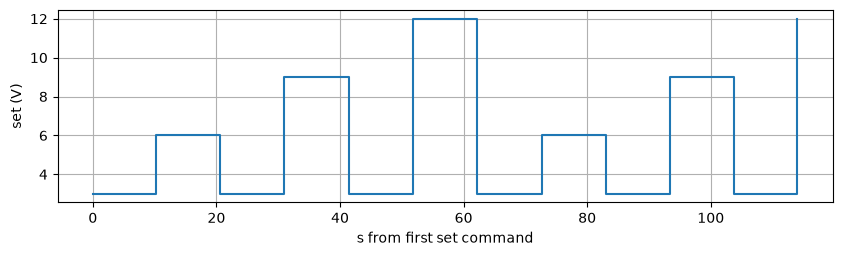

In [3]:
events = pd.read_csv(CAPTURE / "events.csv")
show(events, n=None)
t0 = events.t_host.iloc[0]
for df in (dmm, dps, events):
    df["t"] = df["t_host"] - t0
events.plot(x="t", y="volts", drawstyle="steps-post", figsize=(10, 2.5), grid=True, legend=False, ylabel="set (V)", xlabel="s from first set command");

The commanded levels. From here on `t` is seconds from the first set command for all three logs.

## Raw traces

Both logs on one time axis, with a vertical line at each set command. If the DMM were instantaneous the two traces would lie on top of each other. The DMM trace should look like the DPS trace shifted right by the delay. A shift that grows along the run would mean the two clocks run at different rates.

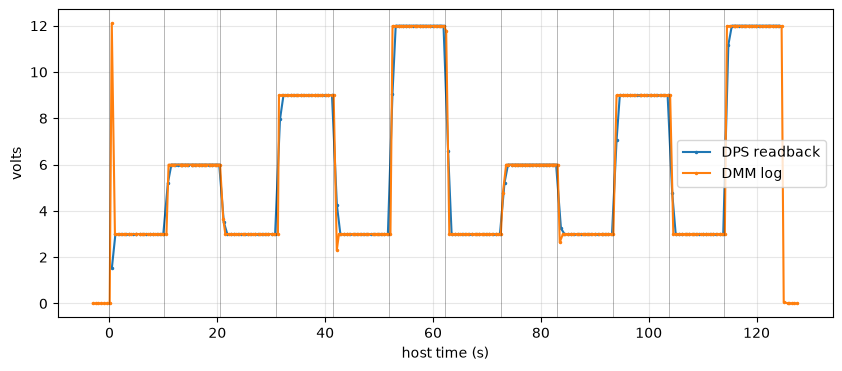

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(dps.t, dps.volts, ".-", ms=3, label="DPS readback")
ax.plot(dmm.t, dmm.value, ".-", ms=3, label="DMM log")
for t in events.t:
    ax.axvline(t, color="k", lw=0.5, alpha=0.4)
ax.set_xlabel("host time (s)"); ax.set_ylabel("volts"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

The two traces sit on top of each other at this scale. Whatever the delay is, it is small against the 10 s steps.

The DMM also sends a packet only every half second or so. That interval matters on its own, since it is the finest time resolution any DMM log in this repo can have.

In [5]:
interval = np.diff(dmm.t_host)
print(f"DMM packet interval: median {np.median(interval):.3f} s, "
      f"5th to 95th percentile {np.percentile(interval, 5):.3f} to {np.percentile(interval, 95):.3f} s")

DMM packet interval: median 0.585 s, 5th to 95th percentile 0.195 to 0.780 s


## Method

Each step gives one measurement of the delay. The voltage goes from the old level to the new one, and both traces cross the midpoint between the two levels at some point. The DPS trace crosses it first, the DMM trace later. The time between the two crossings is the delay for that step.

Both traces are on the host clock, so the DPS's own ramp time cancels. Only the DMM's path from its display to the host log is left: the meter's conversion, its Bluetooth packet, and the host receiving it.

The crossing time is found by linear interpolation between the two samples on either side of the midpoint. For the DPS this is well defined because the readback runs at about 1.5 Hz through a ramp of a few hundred milliseconds. For the DMM the ramp usually falls between two packets, so the interpolation lands somewhere inside a half-second gap. That is a resolution limit of the method, and it appears as scatter in the delays.

The first set command has no DPS trace before it, because the DPS log only starts when the output enables. Step 0 has no delay and is left out.

In [6]:
def crossing(t, v, t_from, t_to, level, rising):
    """Host time at which the trace crosses `level` inside [t_from, t_to), by linear interpolation."""
    m = (t >= t_from) & (t < t_to)
    tt, vv = np.asarray(t[m]), np.asarray(v[m])
    hit = vv >= level if rising else vv <= level
    if not hit.any() or hit[0]:
        return np.nan
    i = int(np.argmax(hit))
    if vv[i] == vv[i - 1]:
        return tt[i]
    return tt[i - 1] + (level - vv[i - 1]) / (vv[i] - vv[i - 1]) * (tt[i] - tt[i - 1])

hold = np.median(np.diff(events.t_host))
rows = []
prev = 0.0
for k, e in events.iterrows():
    level = (prev + e.volts) / 2
    rising = e.volts > prev
    t_dps = crossing(dps.t_host, dps.volts, e.t_host - 2, e.t_host + hold - 1, level, rising)
    t_dmm = crossing(dmm.t_host, dmm.value, e.t_host - 5, e.t_host + hold - 1, level, rising)
    rows.append({"step": k, "from_v": prev, "to_v": e.volts, "dps_cross_s": t_dps - e.t_host,
                 "dmm_cross_s": t_dmm - e.t_host, "lag_s": t_dmm - t_dps})
    prev = e.volts
lags = pd.DataFrame(rows)
lags

,step,from_v,to_v,dps_cross_s,dmm_cross_s,lag_s
0,0,0.0,3.0,NaN,0.084383,NaN
1,1,3.0,6.0,0.377079,0.579390,0.202311
2,2,6.0,3.0,0.312459,0.332658,0.020198
3,3,3.0,9.0,0.345840,0.417663,0.071823
4,4,9.0,3.0,0.371731,0.371759,0.000028
5,5,3.0,12.0,0.433289,0.470282,0.036993
6,6,12.0,3.0,0.507856,0.578670,0.070815
7,7,3.0,6.0,0.374482,0.296083,-0.078399
8,8,6.0,3.0,0.292179,0.260302,-0.031877
9,9,3.0,9.0,0.429283,0.347939,-0.081343


One row per step. `dps_cross_s` and `dmm_cross_s` are the crossing times measured from the set command, and `lag_s` is their difference, the delay for that step.

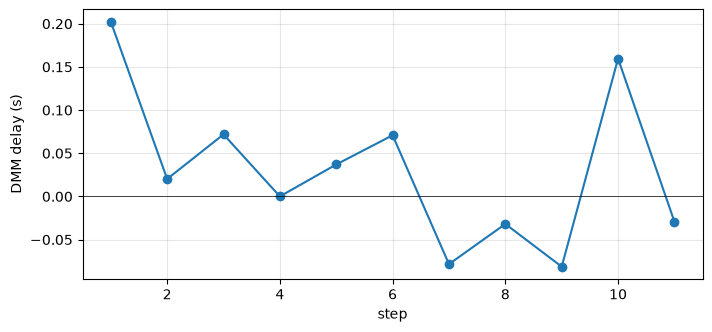

delay: median 0.020 s, min -0.081, max 0.202, n = 11


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lags.step, lags.lag_s, "o-")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("step"); ax.set_ylabel("DMM delay (s)"); ax.grid(alpha=0.3)
plt.show()
ok = lags.lag_s.dropna()
print(f"delay: median {ok.median():.3f} s, min {ok.min():.3f}, max {ok.max():.3f}, n = {len(ok)}")

The delay of each step. The points scatter within a few tenths of a second around a median near zero, with no trend across the run. The scatter is about the size of one DMM packet interval, which is what the interpolation limit predicts. A slightly negative value is possible for the same reason: the interpolated DMM crossing can land before the DPS crossing when the DMM's packet happened to arrive just as the step began.

## Results

The DMM's log lands within a few tenths of a second of the host clock, and the delay does not drift over a two minute run. The packet interval is about half a second, with a spread from a fifth of a second to nearly a second.

The result file carries the median delay with its range as the bounds, the packet interval with its 5th and 95th percentiles, and the number of steps. Later notebooks shift a DMM log by the delay and know not to resolve anything finer than the packet interval.

In [8]:
SPEC_NOTE = "reading accuracy from the B41T+ manual: to add"
results.write("0-instruments", "dmm", CAPTURE, notes=SPEC_NOTE,
              lag_s=results.quantity(ok.median(), ok.min(), ok.max(), "s"),
              packet_interval_s=results.quantity(np.median(interval), np.percentile(interval, 5), np.percentile(interval, 95), "s"),
              steps=results.quantity(len(ok), unit="count"))

PosixPath('stages/0-instruments/dmm/results.json')

## Limitations

- The method resolves the delay to about one DMM packet interval. Eleven steps narrow the median but not the floor on any single step.
- The run is two minutes long. A clock rate difference small enough to hide in two minutes would show in an hour-long thermal log. The clock-sync experiment covers that with the clapper.
- The DMM was on DC V. The delay and the packet rate may differ in other functions.
- The DPS output came up at its previous setting for a moment when enabled, see the first plot. Not a DMM matter, but a DPS habit the later stages have to allow for.

## Open questions

- Whether the packet rate and the delay depend on the DMM's function. A repeat of this capture with the DMM on ohms, and one on temperature with the thermocouple in a bath, would say. The thermocouple experiment reads the temperature mode's packet interval from its own log as a first check.

## Conclusion

The DMM is a good instrument for a quantity that changes over tens of seconds or longer: a resistance warming up, a case temperature, a supply level. Its log can be placed on the host clock as is, with a delay of a few hundredths of a second and no drift worth correcting over a run of minutes.

It is not a reliable instrument for anything that has to be placed in time closer than about one second. Its packets arrive every half second or so, and up to a second apart, so a step edge in a DMM log is known only to within that interval. The board's own telemetry or the DPS readback is the instrument for edges and for anything faster.

Later experiments should take two things from this run.

- Line DMM logs up with other logs by the delay in the result file, and treat the packet interval as the time resolution of anything read through the DMM.
- Do not have a load that minds a voltage pulse on the DPS when its output is enabled. The output came up at its previous setting for a moment before the new one took hold.